# 08 — Principal Component Analysis (PCA)

## Purpose

In this notebook we use **principal component analysis (PCA)** to examine the dimensional structure of our item sets. 

**Part A: Do our sets of items measure one thing or several?**

1. Do the four gender-role items (Q28–Q31) form **one dimension**?
2. Do the six science and technology items (Q158–Q163) form one dimension, or the **two dimensions** suggested by the Cronbach's alpha results in `04_reclean_full.ipynb`?
3. Which **political culture** items group together? This is **exploratory scale construction**: together with the item content, correlations and Cronbach's alpha, the results help us decide how to build the political culture measures for the moderation analysis in `06_moderation.ipynb`. This is why this notebook is run **before** the moderation notebook.

**Appendix: exploratory PCA on the main study variables.** We also run a PCA on the main study variables (parental education, `mother_more_educated`, the moderators and the gender-role score). This mixes binary, ordinal and composite variables, drops the sample to N = 1,444 and does not directly answer our research question, so we treat it as descriptive appendix work only and do **not** base any conclusions on it.

### A short reminder of what PCA does

PCA takes a set of correlated variables and creates new, uncorrelated variables called **principal components**. Each component is a weighted combination of the original variables:

- **PC1** captures as much of the total variation in the variables as possible, **PC2** captures as much of the remaining variation as possible, and so on.
- The **eigenvalue** of a component tells us how much variance it explains, measured in "number of variables' worth" of variance. Because every variable is standardised to have a variance of 1, a component with an eigenvalue above 1 explains more variance than a single original variable. A common rule of thumb (the **Kaiser criterion**) is to keep components with eigenvalues above 1. This is a guideline, not an absolute rule: we use it **together with** the scree plot and with whether the components make sense given the item content.
- The **component weights** show how strongly each original variable contributes to a component. Variables with large weights of the same sign on a component tend to move together. As in Week 9, we report the values in `pca.components_`. Strictly speaking, these are **component weights** (the coefficients of the eigenvectors), **not** conventional PCA *loadings*. Conventional loadings are the correlations between each variable and each component, and are calculated as `pca.components_.T * np.sqrt(pca.explained_variance_)`. Because the weights are rescaled by the same factor within each component, both give the same pattern within a component. With the weights, the squared values in each component add up to 1 (this is a property of the weights, not of conventional loadings), so we treat weights of about **|0.3| or more** as meaningful. We save both versions to `output/tables/` (`_weights.csv` and `_loadings.csv`), but interpret the weights, as in class.
- The **scree plot** shows the percentage of variance explained by each component. We look for the "elbow", the point where the line flattens out, because components after the elbow add little.

### Limitations of this approach

- We use **unrotated PCA**, because this is the method from class. Unrotated components often mix several groups of items, which makes them harder to read. A **rotated exploratory factor analysis (EFA)** would generally be better for identifying clusters of items.
- PCA here is based on ordinary (Pearson) correlations. Our gender-role items have only **four ordinal response categories**, for which an EFA on **polychoric** correlations would be more rigorous. The 10-point items are closer to continuous, so this matters less for them.
- PCA summarises the variance in the items. It is not a model of an underlying latent variable, so it cannot show that a construct exists or that our labels for it are correct.

## 1. Setup and Data Loading

We use the same packages as in Week 9: `StandardScaler` and `PCA` from `scikit-learn`, and `plotnine` for the scree plots.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools
from plotnine import *  # ggplot-style figures, as used in class
from sklearn.preprocessing import StandardScaler  # standardises variables to mean 0 and SD 1
from sklearn.decomposition import PCA  # principal component analysis
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset (notebooks 04 and 05)
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "WVS_Wave_7_Singapore_Csv_v5.1.csv"  # raw file, only read for the sensitivity check
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset
print(f"Number of respondents: {df.shape[0]}")  # number of rows
print(f"Number of variables: {df.shape[1]}")  # number of columns

Number of respondents: 2012
Number of variables: 46


### 1.1 Helper Functions

We follow the Week 9 steps (choose the variables, scale them, fit the PCA, look at the variance explained, the component weights and the scree plot) several times in this notebook. To avoid repeating the same code, we put these steps into two small functions. Each function contains exactly the code from class. We also bring in the `cronbach_alpha()` function from `02_scale_reliability.ipynb`.

In [3]:
def run_pca(cols, name):
    # Steps 1-4 from Week 9: drop missing values, scale, fit the PCA, and print the variance table and component weights.
    work = df.dropna(subset=cols).copy()  # keep respondents with valid answers on all chosen variables
    X = StandardScaler().fit_transform(work[cols])  # standardise each variable to mean 0 and SD 1
    pca = PCA().fit(X)  # fit the PCA
    pc_names = [f"PC{i}" for i in range(1, len(cols) + 1)]  # names for the components: PC1, PC2, ...

    prop = pca.explained_variance_ratio_  # proportion of the total variance explained by each component
    variance = pd.DataFrame({  # variance table, as in Week 9, plus the eigenvalues
        "Eigenvalue": pca.explained_variance_,  # eigenvalue = variance of each component
        "Standard deviation": pca.explained_variance_ ** 0.5,  # square root of the eigenvalue
        "Proportion of variance": prop,  # share of total variance
        "Cumulative proportion": prop.cumsum(),  # running total of the shares
    }, index=pc_names).T  # one column per component

    weights = pd.DataFrame(pca.components_.T, index=cols, columns=pc_names)  # component weights, as in Week 9
    loadings = weights * np.sqrt(pca.explained_variance_)  # conventional loadings (variable-component correlations)

    variance.to_csv(OUTPUT_TABLES / f"pca_{name}_variance.csv")  # save the variance table
    weights.to_csv(OUTPUT_TABLES / f"pca_{name}_weights.csv")  # save the component weights
    loadings.to_csv(OUTPUT_TABLES / f"pca_{name}_loadings.csv")  # save the conventional loadings, for reference
    print(f"N = {len(work)}\n")  # number of respondents used
    print(variance.round(3))  # print the variance table
    print("\nComponent weights (pca.components_):")  # label for the weights
    print(weights.round(3))  # print the component weights
    return work, X, pca  # return the objects in case we need them later


def scree_plot(pca, title, name):
    # Step 5 from Week 9: scree plot of the percentage of variance explained by each component.
    n = len(pca.explained_variance_ratio_)  # number of components
    scree = pd.DataFrame({"component": range(1, n + 1), "percent": pca.explained_variance_ratio_ * 100})  # data for the plot
    scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")  # text labels above the bars
    p = (
        ggplot(scree, aes("component", "percent"))  # x = component number, y = % variance
        + geom_col(fill="#4C78A8", width=0.7)  # bars
        + geom_line(aes(group=1))  # line connecting the bars
        + geom_point()  # points on the line
        + geom_text(aes(label="label"), nudge_y=1.2, size=9, va="bottom")  # percentage labels
        + scale_x_continuous(breaks=range(1, n + 1))  # one tick per component
        + labs(x="Component", y="Percentage of variance explained", title=title)  # axis labels and title
        + theme_light()  # clean background
    )
    p.save(OUTPUT_FIGURES / f"pca_{name}_scree.png", dpi=300, verbose=False)  # save the figure
    return p  # return the plot so it is displayed


def cronbach_alpha(items):
    # Calculate Cronbach's alpha (same function as in 02_scale_reliability.ipynb).
    k = items.shape[1]  # number of items
    item_variances = items.var(axis=0, ddof=1)  # variance of each item
    total_variance = items.sum(axis=1).var(ddof=1)  # variance of the total scores
    return k / (k - 1) * (1 - item_variances.sum() / total_variance)  # Cronbach's alpha formula

# Part A: Item-Level PCAs

## 2. Gender-Role Items (Q28–Q31)

We first check whether the four reverse-coded gender-role items form one dimension. If they do, we would expect **one component with an eigenvalue above 1** and all four items having weights of the same sign on it.

In [4]:
gender_items = ["Q28_rev", "Q29_rev", "Q30_rev", "Q31_rev"]  # reverse-coded gender items (higher = more traditional)
gender_work, gender_X, gender_pca = run_pca(gender_items, "gender_items")  # run the PCA and print the results

N = 1970

                          PC1    PC2    PC3    PC4
Eigenvalue              2.392  0.792  0.479  0.339
Standard deviation      1.547  0.890  0.692  0.582
Proportion of variance  0.598  0.198  0.120  0.085
Cumulative proportion   0.598  0.796  0.915  1.000

Component weights (pca.components_):
           PC1    PC2    PC3    PC4
Q28_rev  0.365  0.926  0.052  0.087
Q29_rev  0.535 -0.128 -0.685 -0.477
Q30_rev  0.526 -0.211  0.724 -0.394
Q31_rev  0.551 -0.288 -0.059  0.781


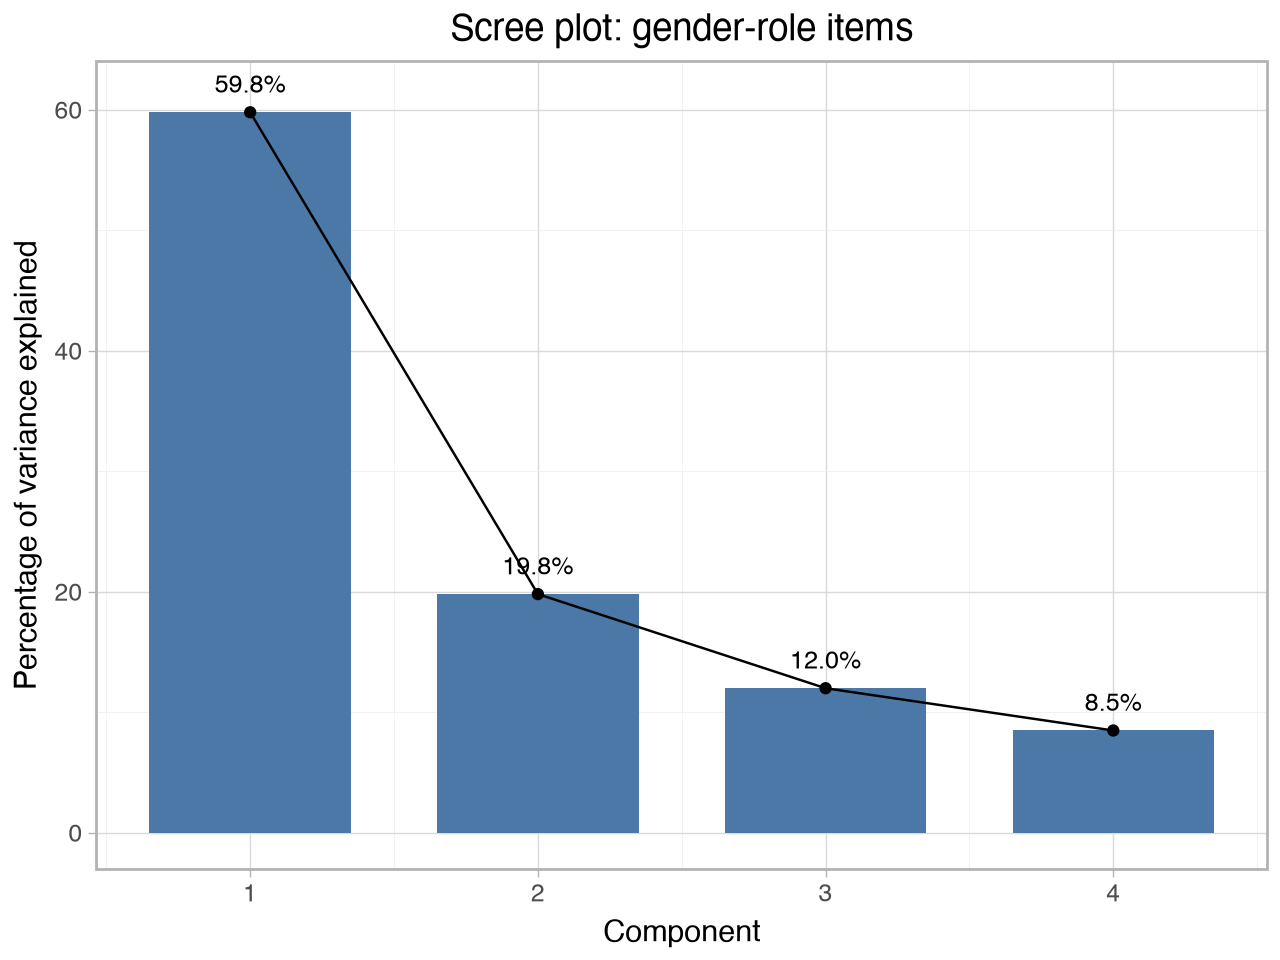

In [5]:
scree_plot(gender_pca, "Scree plot: gender-role items", "gender_items")  # scree plot for the gender items

### Interpretation

**Eigenvalues.** Only **PC1** has an eigenvalue above 1 (**2.392**). It explains **59.8%** of the variance in the four items. The next component has an eigenvalue of only 0.792, and the scree plot drops sharply after PC1 and then flattens out. The Kaiser criterion and the scree plot both point to **one main component**.

**Component weights.** All four items have **positive** weights on PC1 (Q28_rev = 0.365, Q29_rev = 0.535, Q30_rev = 0.526, Q31_rev = 0.551). This means that respondents who give a traditional answer on one item tend to give traditional answers on the others, so PC1 can be read as a general **traditional gender-role attitudes** dimension.

Q28_rev ("when a mother works for pay, the children suffer") has the smallest weight on PC1 and dominates PC2 (weight = 0.926). This suggests that Q28 partly captures something slightly different from the other three items. Q29–Q31 are about whether men are better suited to leadership and education, while Q28 is about childcare and the family. PC2's eigenvalue is below 1, so this is a secondary pattern, but it is not negligible: Q28 behaves somewhat differently from the other three items, and the composite partly mixes a family/childcare item with three items about men's and women's suitability for leadership and education.

**Conclusion:** we treat this PCA as **supplementary** evidence, consistent with the Cronbach's alpha result from `02_scale_reliability.ipynb` (α = .767), that Q28–Q31 share **one broad dimension**, which supports combining them into the `traditional_gender_attitudes` score. Q28 fits this dimension less well than the others. Because the items have only four ordinal categories, an EFA on polychoric correlations would be a more rigorous test. Like alpha, the PCA does not show *what* the shared dimension measures. The label "traditional gender-role attitudes" comes from the item content.

## 3. Science and Technology Items (Q158–Q163)

In `04_reclean_full.ipynb`, the six science items had a low Cronbach's alpha (α = .460), and the correlations suggested two groups: **science optimism** (Q158, Q159, Q163) and **science and faith/morality** (Q160_rev, Q161_rev), with Q162_rev standing apart. We now check whether PCA finds the same structure. All items are coded so that higher = more positive about science.

In [6]:
science_items = ["Q158", "Q159", "Q160_rev", "Q161_rev", "Q162_rev", "Q163"]  # the six direction-aligned science items
sci_work, sci_X, sci_pca = run_pca(science_items, "science_items")  # run the PCA and print the results

N = 1977

                          PC1    PC2    PC3    PC4    PC5    PC6
Eigenvalue              1.997  1.590  0.970  0.702  0.454  0.290
Standard deviation      1.413  1.261  0.985  0.838  0.674  0.539
Proportion of variance  0.333  0.265  0.162  0.117  0.076  0.048
Cumulative proportion   0.333  0.598  0.759  0.876  0.952  1.000

Component weights (pca.components_):
            PC1    PC2    PC3    PC4    PC5    PC6
Q158      0.607  0.171  0.008 -0.321  0.054  0.704
Q159      0.607  0.151 -0.109 -0.317 -0.126 -0.693
Q160_rev -0.159  0.650 -0.213  0.138 -0.691  0.098
Q161_rev -0.104  0.677 -0.134  0.084  0.706 -0.089
Q162_rev  0.197  0.214  0.886  0.349 -0.058 -0.068
Q163      0.433 -0.147 -0.373  0.806  0.042  0.030


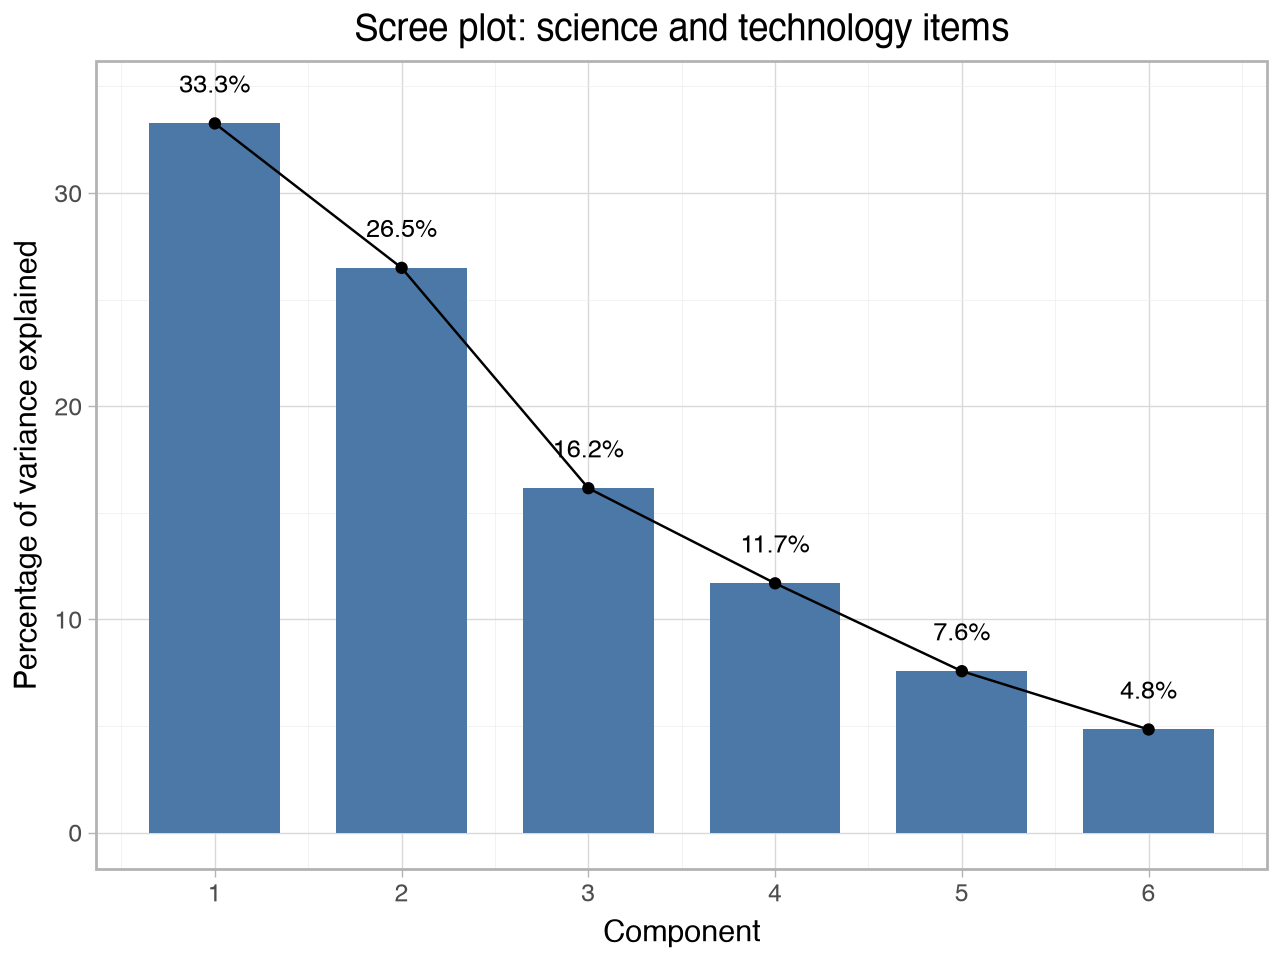

In [7]:
scree_plot(sci_pca, "Scree plot: science and technology items", "science_items")  # scree plot for the science items

### Interpretation

**Eigenvalues.** Two components have eigenvalues above 1: **PC1 = 1.997** (33.3% of the variance) and **PC2 = 1.590** (26.5%). Together they explain **59.8%** of the variance. PC3 is only just below the cut-off (0.970, 16.2%), so the Kaiser rule alone does not clearly separate it from PC2. The scree plot shows a clear drop after PC2.

**Component weights.**
- **PC1** is defined by Q158 (0.607), Q159 (0.607) and Q163 (0.433). These are the three items about the practical benefits of science (healthier and easier lives, more opportunities, the world being better off). This is our **science optimism** dimension.
- **PC2** is defined by Q160_rev (0.650) and Q161_rev (0.677). These are the two items about faith and morality. This is our **science and faith/morality** dimension.
- **PC3** is almost entirely Q162_rev (0.886), "it is not important for me to know about science in my daily life" (reversed). So Q162 behaves as a **distinct item** that does not move with either group.

**Conclusion:** the PCA supports the two-dimensional structure suggested by the item correlations and Cronbach's alpha in `04_reclean_full.ipynb`. The six science items do **not** form one scale (their combined alpha was only .460): being optimistic about science's benefits is largely separate from being concerned about its moral effects. We therefore use the two sub-scales, **`science_optimism`** (α = .698) and **`science_faith_morality`** (α = .705), as two separate moderators.

**Why Q162 is left out.** The PCA shows that Q162 behaves differently from the other items, but it does not by itself show that Q162 should be discarded (PC3's eigenvalue, 0.970, is almost 1). We leave Q162 out for a **conceptual** reason: it asks whether knowing about science is important *to the respondent personally in daily life*. That is about personal relevance or interest, which fits neither of the two moderator constructs we intend to measure (beliefs about science's benefits, and about its effects on faith and morality).

## 4. Political Culture Items: Exploratory Scale Construction

This section is **exploratory scale construction**. There is no established scale for these items in our project, so we use the PCA, together with the item content, correlations and Cronbach's alpha, to decide how to group them. The components here are messier than for the gender and science items, and the names we give to any group of items rest on **theory and item wording**, not on the statistical clustering alone.

We examine the political culture items:

- **Q241–Q248:** how essential each item is as a characteristic of democracy
- **Q250:** importance of living in a democracy
- **Q251:** how democratically Singapore is governed
- **Q252:** satisfaction with the political system
- **Q253_rev:** respect for human rights (reversed, so higher = more respect)

Two items are handled separately:

- **Q249 ("women have the same rights as men")** is left out because it overlaps with our outcome (see Section 4.3).
- **Q240 (left–right self-placement)** is left out of this PCA because it is missing for 13.3% of respondents, mostly because of "don't know" answers. Including it would drop about 170 extra respondents from the PCA. It is also conceptually different: it measures ideology rather than views about democracy. We keep Q240 as a **single-item** moderator.

In [8]:
political_items = [f"Q{i}" for i in range(241, 249)] + ["Q250", "Q251", "Q252", "Q253_rev"]  # political items for the PCA
pol_work, pol_X, pol_pca = run_pca(political_items, "political_items")  # run the PCA and print the results

N = 1755

                          PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
Eigenvalue              2.672  1.973  1.728  0.927  0.792  0.699  0.648   
Standard deviation      1.635  1.404  1.314  0.963  0.890  0.836  0.805   
Proportion of variance  0.223  0.164  0.144  0.077  0.066  0.058  0.054   
Cumulative proportion   0.223  0.387  0.531  0.608  0.674  0.732  0.786   

                          PC8    PC9   PC10   PC11   PC12  
Eigenvalue              0.631  0.580  0.527  0.518  0.313  
Standard deviation      0.794  0.762  0.726  0.720  0.560  
Proportion of variance  0.053  0.048  0.044  0.043  0.026  
Cumulative proportion   0.839  0.887  0.931  0.974  1.000  

Component weights (pca.components_):
            PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9  \
Q241      0.303  0.156  0.290  0.246  0.551  0.263 -0.148 -0.453  0.129   
Q242      0.240  0.396 -0.256  0.075  0.045  0.236 -0.514  0.062 -0.148   
Q243      0.103 -0.282  0.494 -0.090 -0.299  0.241 

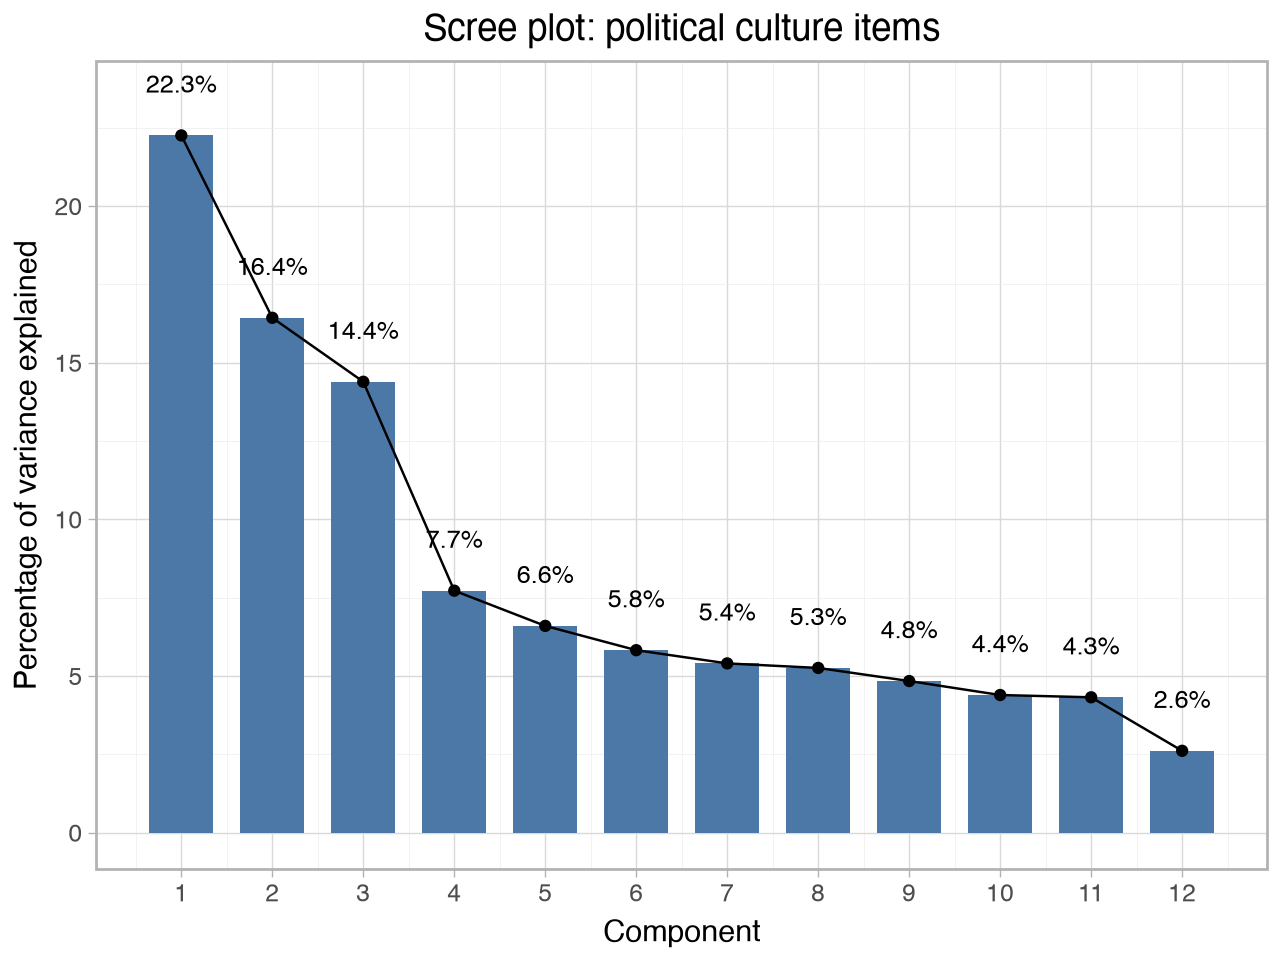

In [9]:
scree_plot(pol_pca, "Scree plot: political culture items", "political_items")  # scree plot for the political items

### Interpretation

**Eigenvalues.** Three components have eigenvalues above 1: **PC1 = 2.672** (22.3%), **PC2 = 1.973** (16.4%) and **PC3 = 1.728** (14.4%). Together they explain **53.1%** of the variance. PC4 is just below 1 (0.927), and the scree plot flattens out after PC3. Because PC4 is so close to the cut-off, the exact number of dimensions is a judgement call rather than something the Kaiser rule settles. Either way, the political items cover **several different dimensions**, which suggests that they should not be forced into one index.

**Component weights.**
- **PC1:** all twelve items have **positive** weights (0.10 to 0.38). This kind of component often reflects a **general response tendency**: some respondents give higher ratings to *every* item, whatever it says. Because it mixes pro-democratic and authoritarian items, it does not represent a meaningful political attitude.
- **PC2** contrasts two groups of items:
  - **Positive weights:** Q242 religious authorities interpret the laws (0.396), Q247 the state makes incomes equal (0.330), Q245 the army takes over (0.295) and Q244 unemployment aid (0.227). Q242 and Q245 are **authoritarian notions of democracy**. Q247 and Q244 are economic items that also load here (see Section 4.1 for why we do not treat Q247 as authoritarian).
  - **Negative weights:** Q251 how democratic Singapore is (−0.381), Q252 satisfaction with the political system (−0.381), Q253_rev respect for human rights (−0.342) and Q243 free elections (−0.282). These are mostly **evaluations of Singapore's political system**.
- **PC3** has its largest weights for Q246 civil rights (0.513) and Q243 free elections (0.494), followed by the economic items Q241 (0.290) and Q244 (0.281). Q242 (−0.256), Q251 (−0.256) and Q252 (−0.247) have negative weights. Based on the content of its strongest items, we read this mainly as a **liberal notions of democracy** dimension.

The three economic items (Q241, Q244, Q247) do **not** form a component of their own. They are split between the authoritarian side (PC2) and the liberal side (PC3).

These descriptions of PC2 and PC3 are **our interpretations** of mixed components, not labels the PCA provides. Because the PCA without rotation spreads each group of items across several components, we check the groups with the item content, correlations and Cronbach's alpha below before building any index.

### 4.1 Checking the Groups with Correlations and Cronbach's Alpha

PCA without rotation (the method we used in class) can produce components that mix several groups of items, which makes the weights harder to read. A rotated EFA would generally be better for identifying item clusters. To check the groups suggested by the weights, we look at the item correlations and calculate Cronbach's alpha for each candidate sub-index.

**Item content comes first.** We start from the conceptual groups described in our plan (authoritarian, liberal and economic notions of democracy, and evaluations of Singapore's political system), which follow the usual reading of these WVS items. The PCA, correlations and alpha are then used to **check** these groups. We do not add or drop items only because doing so raises alpha: a higher alpha shows that an item is answered *consistently* with the others, not that it measures the same concept.

In [10]:
df[political_items].corr().round(2)  # Pearson correlations between the political items

,Q241,Q242,Q243,Q244,Q245,Q246,Q247,Q248,Q250,Q251,Q252,Q253_rev
Q241,1.00,0.18,0.16,0.36,0.13,0.20,0.27,0.17,0.18,0.06,0.07,0.01
Q242,0.18,1.00,-0.24,0.16,0.36,-0.12,0.35,0.26,-0.06,0.05,0.02,-0.02
Q243,0.16,-0.24,1.00,0.12,-0.12,0.42,-0.02,0.02,0.24,0.10,0.12,0.06
Q244,0.36,0.16,0.12,1.00,0.21,0.23,0.38,0.27,0.13,0.07,0.07,0.02
Q245,0.13,0.36,-0.12,0.21,1.00,-0.03,0.28,0.29,0.02,0.10,0.09,0.03
Q246,0.20,-0.12,0.42,0.23,-0.03,1.00,0.16,0.09,0.14,0.02,0.06,0.06
Q247,0.27,0.35,-0.02,0.38,0.28,0.16,1.00,0.33,0.04,0.04,0.06,0.03
Q248,0.17,0.26,0.02,0.27,0.29,0.09,0.33,1.00,0.11,0.24,0.24,0.15
Q250,0.18,-0.06,0.24,0.13,0.02,0.14,0.04,0.11,1.00,0.34,0.21,0.09
Q251,0.06,0.05,0.10,0.07,0.10,0.02,0.04,0.24,0.34,1.00,0.66,0.41


In [11]:
candidates = {  # candidate sub-indices to compare
    "Authoritarian (Q242, Q245, Q248)": ["Q242", "Q245", "Q248"],  # authoritarian items only
    "Authoritarian + equal incomes (Q242, Q245, Q247, Q248)": ["Q242", "Q245", "Q247", "Q248"],  # adds Q247
    "Economic (Q241, Q244, Q247)": ["Q241", "Q244", "Q247"],  # all three economic items
    "Economic without Q247 (Q241, Q244)": ["Q241", "Q244"],  # economic items without equal incomes
    "Liberal (Q243, Q246)": ["Q243", "Q246"],  # pro-democratic items
    "Liberal + importance of democracy (Q243, Q246, Q250)": ["Q243", "Q246", "Q250"],  # adds Q250
    "Regime evaluation (Q251, Q252)": ["Q251", "Q252"],  # evaluation of Singapore's democracy and system
    "Regime evaluation + human rights (Q251, Q252, Q253_rev)": ["Q251", "Q252", "Q253_rev"],  # adds Q253_rev
}

alpha_table = pd.DataFrame([  # one row per candidate sub-index
    {"Sub-index": label, "N (complete cases)": len(df[cols].dropna()),  # name and sample size
     "Cronbach's alpha": round(cronbach_alpha(df[cols].dropna()), 3)}  # alpha
    for label, cols in candidates.items()])

alpha_table.to_csv(OUTPUT_TABLES / "political_subindex_alphas.csv", index=False)  # save the table
alpha_table  # display the table

,Sub-index,N (complete cases),Cronbach's alpha
0,"Authoritarian (Q242, Q245, Q248)",1827,0.569
1,"Authoritarian + equal incomes (Q242, Q245, Q24...",1819,0.643
2,"Economic (Q241, Q244, Q247)",1883,0.600
3,"Economic without Q247 (Q241, Q244)",1906,0.529
4,"Liberal (Q243, Q246)",1872,0.592
5,"Liberal + importance of democracy (Q243, Q246,...",1859,0.527
6,"Regime evaluation (Q251, Q252)",1955,0.797
7,"Regime evaluation + human rights (Q251, Q252, ...",1927,0.704


### Interpretation

**Conceptual groups.** Based on the wording of the items in the WVS questionnaire, we expected these groups:

| Conceptual group | Items | Index built? |
|---|---|---|
| **Authoritarian notions** of democracy | Q242 religious authorities ultimately interpret the laws; Q245 the army takes over when government is incompetent; Q248 people obey their rulers | Yes: `authoritarian_democracy` |
| **Liberal notions** of democracy | Q243 people choose their leaders in free elections; Q246 civil rights protect people from state oppression (Q249, women's equal rights, would also belong here but overlaps with our outcome, see Section 4.3) | Yes: `liberal_democracy` |
| **Social / economic notions** of democracy | Q241 governments tax the rich and subsidise the poor; Q244 people receive state aid for unemployment; Q247 the state makes people's incomes equal | No (see below) |
| **Evaluation of Singapore's political system** | Q251 how democratically the country is governed; Q252 satisfaction with the political system; (Q253 respect for human rights) | Yes: `regime_evaluation` (Q251, Q252) |

**Correlations.** The correlation table mostly supports these groups:

- **Q251 and Q252** are strongly correlated (**r = .66**), and both correlate moderately with Q253_rev (r = .41 and .45).
- **Q243 and Q246** (free elections and civil rights) correlate **r = .42**, and both are *negatively* related to Q242 (religious authorities interpret the laws, r = −.24 and −.12).
- **Q242, Q245 and Q248** correlate between .26 and .36.
- **Q247** (equal incomes) correlates about as strongly with the authoritarian items (r = .28 to .35) as with the other economic items (r = .27 and .38). This is the one item that does not sit clearly in its conceptual group.

**Cronbach's alpha (used as a check, not as a rule for choosing items).**
- **Authoritarian notions (Q242, Q245, Q248): α = .569** (N = 1,827). This is below .60, so the reliability of this index is **modest / questionable**.
  - **Why Q247 is left out.** Adding Q247 would raise alpha to .643, and Q247 also had a large positive weight alongside the authoritarian items on PC2. But "the state makes people's incomes equal" is, by its content, an **economic-egalitarian (social) notion** of democracy, not an authoritarian one. Its correlation with the authoritarian items may reflect a shared view that a strong, interventionist state is part of democracy, or the general response tendency on PC1. It does not by itself make income equality an authoritarian idea. Because conceptual fit comes first, the main index uses only the three clearly authoritarian items.
  - **Sensitivity check.** We also save the four-item version (`authoritarian_democracy_q247`: Q242, Q245, Q247, Q248) and re-run the key analyses with it in `06_moderation.ipynb` (Section 8.3) and `07_multivariate_models.ipynb` (Section 8.5). If the conclusions are the same with both versions, they do not depend on this decision.
- **Liberal notions (Q243, Q246): α = .592** (N = 1,872; inter-item r = .42). This is also below .60, so `liberal_democracy` has **modest / questionable reliability** and should **not** be treated as a strong scale. It has only two items, and we keep it because the two items share a clear common idea (the core liberal features of democracy) and had large weights on PC3, not because its reliability is good. Q250 (importance of living in a democracy) is left out because it measures general **support** for democracy rather than which features count as democratic. Adding it would also lower alpha to .527.
- **Regime evaluation (Q251, Q252): α = .797**, which is acceptable. Q253 (respect for human rights) is also an evaluation of the political system, so it fits conceptually. We leave it out mainly because it uses a different response scale (1–4 instead of 1–10) and asks about one specific aspect, human rights. Alpha with Q253_rev is still acceptable (.704), so this is a judgement call.
- **Social / economic notions (Q241, Q244, Q247):** α = .600 (only .529 without Q247). These items form a coherent conceptual group, but the PCA did not find a separate component for them, and economic notions of democracy are not one of the moderators in our research question. We therefore **do not** build an economic index, and Q241, Q244 and Q247 are not used as moderators.

**These are exploratory measures, not validated scales.** We built the political sub-indices by grouping items and checking the groups with PCA, correlations and alpha in **this same Singapore sample**, which is also the sample we use to test our hypotheses. The indices have not been validated in other samples (for example other WVS countries or waves) or with confirmatory methods such as confirmatory factor analysis. Their labels ("authoritarian", "liberal", "regime evaluation") are our interpretations of the item wording, not established constructs. Two of the three indices have alpha below .60, so they contain considerable measurement error. Measurement error tends to weaken associations and interaction effects, and results for these indices should be interpreted with caution.

### 4.2 Building the Political Culture Measures

Based on the item content, and checked against the PCA, the correlations and the alphas, we build three **exploratory** sub-indices as the mean of their items (only for respondents who answered all items, as in our other composites). All are on a 1–10 scale. We also build the four-item authoritarian index that includes Q247, which is used **only** as a sensitivity check.

In [12]:
df["authoritarian_democracy"] = df[["Q242", "Q245", "Q248"]].mean(axis=1, skipna=False)  # authoritarian notions (main index)
df["authoritarian_democracy_q247"] = df[["Q242", "Q245", "Q247", "Q248"]].mean(axis=1, skipna=False)  # sensitivity version that adds Q247
df["liberal_democracy"] = df[["Q243", "Q246"]].mean(axis=1, skipna=False)  # liberal notions of democracy
df["regime_evaluation"] = df[["Q251", "Q252"]].mean(axis=1, skipna=False)  # evaluation of Singapore's political system

political_measures = ["authoritarian_democracy", "liberal_democracy", "regime_evaluation", "Q240"]  # the political moderators
desc = df[political_measures].agg(["count", "mean", "std", "median", "min", "max"]).T  # descriptive statistics
desc["count"] = desc["count"].astype(int)  # show counts as whole numbers
print(desc.round(2))  # print the descriptives
print("\nCorrelations between the political measures:")  # label
print(df[political_measures].corr().round(2))  # correlations between the measures
print(f"\nr between authoritarian_democracy and the version with Q247 = "
      f"{df['authoritarian_democracy'].corr(df['authoritarian_democracy_q247']):.3f} "
      f"(N with Q247 = {df['authoritarian_democracy_q247'].notna().sum()})")  # how similar the two versions are

                         count  mean   std  median  min   max
authoritarian_democracy   1827  4.12  1.79     4.0  1.0  10.0
liberal_democracy         1872  7.65  1.83     8.0  1.0  10.0
regime_evaluation         1955  6.73  1.70     7.0  1.0  10.0
Q240                      1745  5.08  2.02     5.0  1.0  10.0

Correlations between the political measures:
                         authoritarian_democracy  liberal_democracy  \
authoritarian_democracy                     1.00              -0.11   
liberal_democracy                          -0.11               1.00   
regime_evaluation                           0.19               0.09   
Q240                                        0.14              -0.03   

                         regime_evaluation  Q240  
authoritarian_democracy               0.19  0.14  
liberal_democracy                     0.09 -0.03  
regime_evaluation                     1.00  0.14  
Q240                                  0.14  1.00  

r between authoritarian_democrac

### Interpretation

We now have **four political culture measures** for the moderation analysis:

| Measure | Items | α | N | Mean (SD) | Higher score means… |
|---|---|---|---|---|---|
| `authoritarian_democracy` | Q242, Q245, Q248 | .569 (questionable) | 1,827 | 4.12 (1.79) | Seeing religious authorities interpreting the laws, army takeovers and obedience to rulers as more essential to democracy |
| `liberal_democracy` | Q243, Q246 | .592 (questionable) | 1,872 | 7.65 (1.83) | Seeing free elections and civil rights as more essential to democracy |
| `regime_evaluation` | Q251, Q252 | .797 | 1,955 | 6.73 (1.70) | Rating Singapore as more democratic and being more satisfied with its political system |
| `Q240` (single item) | Q240 | – | 1,745 | 5.08 (2.02) | Placing oneself further to the right |

On average, respondents see liberal features as much more essential to democracy (mean = 7.65) than authoritarian ones (mean = 4.12), and they are fairly positive about Singapore's political system.

The four measures are only **weakly correlated** with each other (all |r| ≤ .19). Seeing liberal features as essential is only weakly (negatively) related to seeing authoritarian features as essential (r = −.11). Many respondents rate both types of features as fairly essential, which matches the "general response tendency" we saw on PC1. These weak correlations suggest that the measures capture **different aspects** of political culture, so we test each of them separately as a moderator.

The four-item version that includes Q247 (`authoritarian_democracy_q247`) correlates **r = .937** with the main three-item index (N = 1,819), so the two versions rank respondents very similarly. We still check in notebooks 06 and 07 that the conclusions do not depend on this choice.

### 4.3 Why Q249 Is Left Out

Q249 asks how essential it is for democracy that "women have the same rights as men". This is very close to what our outcome measures, so including it in a political culture index would partly mean predicting gender-role attitudes with another measure of gender-role attitudes. Below we compare its correlation with the outcome to that of the other democracy items.

In [13]:
democracy_items = [f"Q{i}" for i in range(241, 250)]  # Q241-Q249
corr_with_outcome = df[democracy_items + ["traditional_gender_attitudes"]].corr()["traditional_gender_attitudes"]  # correlations
corr_with_outcome.drop("traditional_gender_attitudes").round(3).to_frame("r with traditional gender-role attitudes")  # display

,r with traditional gender-role attitudes
Q241,0.113
Q242,0.261
Q243,-0.104
Q244,0.172
Q245,0.184
Q246,-0.083
Q247,0.187
Q248,0.203
Q249,-0.171


### Interpretation

Q249 is **negatively** correlated with traditional gender-role attitudes (**r = −.171**): respondents who see equal rights for women as essential to democracy hold less traditional gender-role attitudes. This is what we would expect, since both measure support for gender equality.

The correlation is moderate rather than very large, and some authoritarian items are actually more strongly related to the outcome (e.g. Q242, **r = .261**). However, the reason for excluding Q249 is **conceptual**, not just statistical: Q249 asks directly about women's rights, so it is essentially another gender-equality item. Including it in a political culture index would make any link between "political culture" and gender-role attitudes partly circular. The other items do not have this problem, because they do not mention gender. We therefore leave **Q249 out of all indices**.

The table also shows an interesting pattern that we will return to in the models: the three authoritarian items (Q242, Q245, Q248), and also Q247, are positively correlated with traditional gender-role attitudes (r = .18 to .26), while the two liberal items (Q243, Q246) are negatively correlated (r = −.10 and −.08).

### 4.4 Sensitivity Check: Recoding 0 ("Against Democracy") as 1

In `04_reclean_full.ipynb` we treated the rare code 0 ("it is against democracy") in Q241–Q249 as missing. To check that this decision does not affect our results, we rebuild the two sub-indices that use these items with 0 recoded as **1** ("not an essential characteristic") instead, and compare the two versions. We read the original values from the raw file (reading only; the file is not changed).

In [14]:
raw = pd.read_csv(RAW_PATH, sep=";", index_col=False)  # read the raw data (with the column-alignment fix from notebook 04)
alt = raw[[f"Q{i}" for i in range(241, 249)]].copy()  # the democracy items used in the sub-indices
alt = alt.mask(alt < 0)  # negative codes are still missing
alt = alt.replace(0, 1)  # the alternative decision: 0 ("against democracy") becomes 1

alt_auth = alt[["Q242", "Q245", "Q248"]].mean(axis=1, skipna=False)  # authoritarian index, alternative coding
alt_lib = alt[["Q243", "Q246"]].mean(axis=1, skipna=False)  # liberal index, alternative coding

sensitivity = pd.DataFrame({  # compare the two versions
    "Sub-index": ["authoritarian_democracy", "liberal_democracy"],  # names
    "N (0 = missing)": [df["authoritarian_democracy"].notna().sum(), df["liberal_democracy"].notna().sum()],  # N, main version
    "N (0 = 1)": [alt_auth.notna().sum(), alt_lib.notna().sum()],  # N, alternative version
    "Mean (0 = missing)": [df["authoritarian_democracy"].mean(), df["liberal_democracy"].mean()],  # mean, main version
    "Mean (0 = 1)": [alt_auth.mean(), alt_lib.mean()],  # mean, alternative version
    "r between versions": [df["authoritarian_democracy"].corr(alt_auth), df["liberal_democracy"].corr(alt_lib)],  # correlation
})
sensitivity.round(3)  # display the table

,Sub-index,N (0 = missing),N (0 = 1),Mean (0 = missing),Mean (0 = 1),r between versions
0,authoritarian_democracy,1827,1836,4.124,4.118,1.0
1,liberal_democracy,1872,1875,7.649,7.642,1.0


### Interpretation

The two codings give practically **identical** results. Recoding 0 as 1 only adds **9** respondents to the authoritarian index (1,836 instead of 1,827) and **3** to the liberal index (1,875 instead of 1,872). The means barely change (4.124 vs. 4.118, and 7.649 vs. 7.642), and the two versions of each index are correlated **r = 1.000** (rounded). Our decision to treat 0 as missing therefore has **no meaningful effect** on the political culture measures.

## 5. Saving the Political Culture Sub-Indices

We save the three new political culture sub-indices, and the four-item authoritarian version used for sensitivity checks, into the cleaned dataset so that `06_moderation.ipynb` and `07_multivariate_models.ipynb` can use them.

In [15]:
df.to_csv(DATA_PATH, index=False)  # save the dataset with the new sub-indices

check = pd.read_csv(DATA_PATH)  # reload to confirm
print([c for c in ["authoritarian_democracy", "authoritarian_democracy_q247", "liberal_democracy", "regime_evaluation"] if c in check.columns])  # saved columns
print(f"Number of variables: {check.shape[1]}")  # number of columns now in the file

['authoritarian_democracy', 'authoritarian_democracy_q247', 'liberal_democracy', 'regime_evaluation']
Number of variables: 50


# Appendix: Exploratory PCA on the Main Study Variables

## A.1 Choosing the Variables

**This appendix is descriptive only and is not used for any of our conclusions.** It mixes binary, ordinal and composite variables, which PCA does not handle well, it drops the sample to the respondents with complete data on every variable, and it does not directly answer our research question. Our research question is answered by the correlations in `03_correlations.ipynb` and the regression models in `06_moderation.ipynb` and `07_multivariate_models.ipynb`. We keep the PCA here only as an overview of how the variables vary together:

- **Parental education:** mother's education (Q277R), father's education (Q278R) and `mother_more_educated`
- **Religiosity:** importance of God (Q164)
- **Science and technology:** `science_optimism` and `science_faith_morality`
- **Political culture:** `authoritarian_democracy`, `liberal_democracy`, `regime_evaluation` and left–right self-placement (Q240)
- **Outcome:** `traditional_gender_attitudes`

**A note on variable types:** PCA is designed for continuous variables, because it is based on correlations, which assume that a variable can vary smoothly. `mother_more_educated` is a yes/no (0/1) variable, and only 6% of respondents have a 1. Binary variables like this tend to have weaker correlations with everything else. Q277R and Q278R are also ordinal with only three categories. The weights for these variables should therefore be read with caution. (MCA, from Week 10, is designed for categorical variables, but most of our variables are not categorical either, so no single method fits this mix well.)

In [16]:
main_vars = ["Q277R", "Q278R", "mother_more_educated",  # parental education
             "Q164",  # religiosity
             "science_optimism", "science_faith_morality",  # science and technology
             "authoritarian_democracy", "liberal_democracy", "regime_evaluation", "Q240",  # political culture
             "traditional_gender_attitudes"]  # outcome

df[main_vars].dropna().describe().round(2)  # summary of the variables among respondents with complete data

,Q277R,Q278R,mother_more_educated,Q164,science_optimism,science_faith_morality,authoritarian_democracy,liberal_democracy,regime_evaluation,Q240,traditional_gender_attitudes
count,1444.00,1444.00,1444.00,1444.00,1444.00,1444.00,1444.00,1444.00,1444.00,1444.00,1444.00
mean,1.41,1.56,0.06,6.63,7.22,5.26,4.15,7.58,6.80,5.05,2.11
std,0.66,0.73,0.24,3.00,1.47,2.02,1.78,1.80,1.66,2.02,0.54
min,1.00,1.00,0.00,1.00,1.33,1.00,1.00,1.00,1.00,1.00,1.00
25%,1.00,1.00,0.00,5.00,6.33,4.00,3.00,6.50,6.00,4.00,1.75
50%,1.00,1.00,0.00,7.00,7.33,5.00,4.00,8.00,7.00,5.00,2.00
75%,2.00,2.00,0.00,10.00,8.33,6.50,5.33,9.00,8.00,6.00,2.50
max,3.00,3.00,1.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,3.75


## A.2 Scale, Then Fit

In [17]:
main_work, main_X, main_pca = run_pca(main_vars, "main_variables")  # run the PCA and print the results

N = 1444

                          PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
Eigenvalue              2.169  1.582  1.332  1.073  0.959  0.914  0.865   
Standard deviation      1.473  1.258  1.154  1.036  0.979  0.956  0.930   
Proportion of variance  0.197  0.144  0.121  0.097  0.087  0.083  0.079   
Cumulative proportion   0.197  0.341  0.462  0.559  0.646  0.729  0.808   

                          PC8    PC9   PC10   PC11  
Eigenvalue              0.721  0.670  0.540  0.181  
Standard deviation      0.849  0.819  0.735  0.426  
Proportion of variance  0.066  0.061  0.049  0.016  
Cumulative proportion   0.874  0.934  0.984  1.000  

Component weights (pca.components_):
                                PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
Q277R                         0.484  0.305  0.427  0.066  0.041 -0.065  0.059   
Q278R                         0.410  0.280  0.383 -0.475  0.065  0.014  0.035   
mother_more_educated          0.220  0.105  0.150  0.872  0.019 -0.0

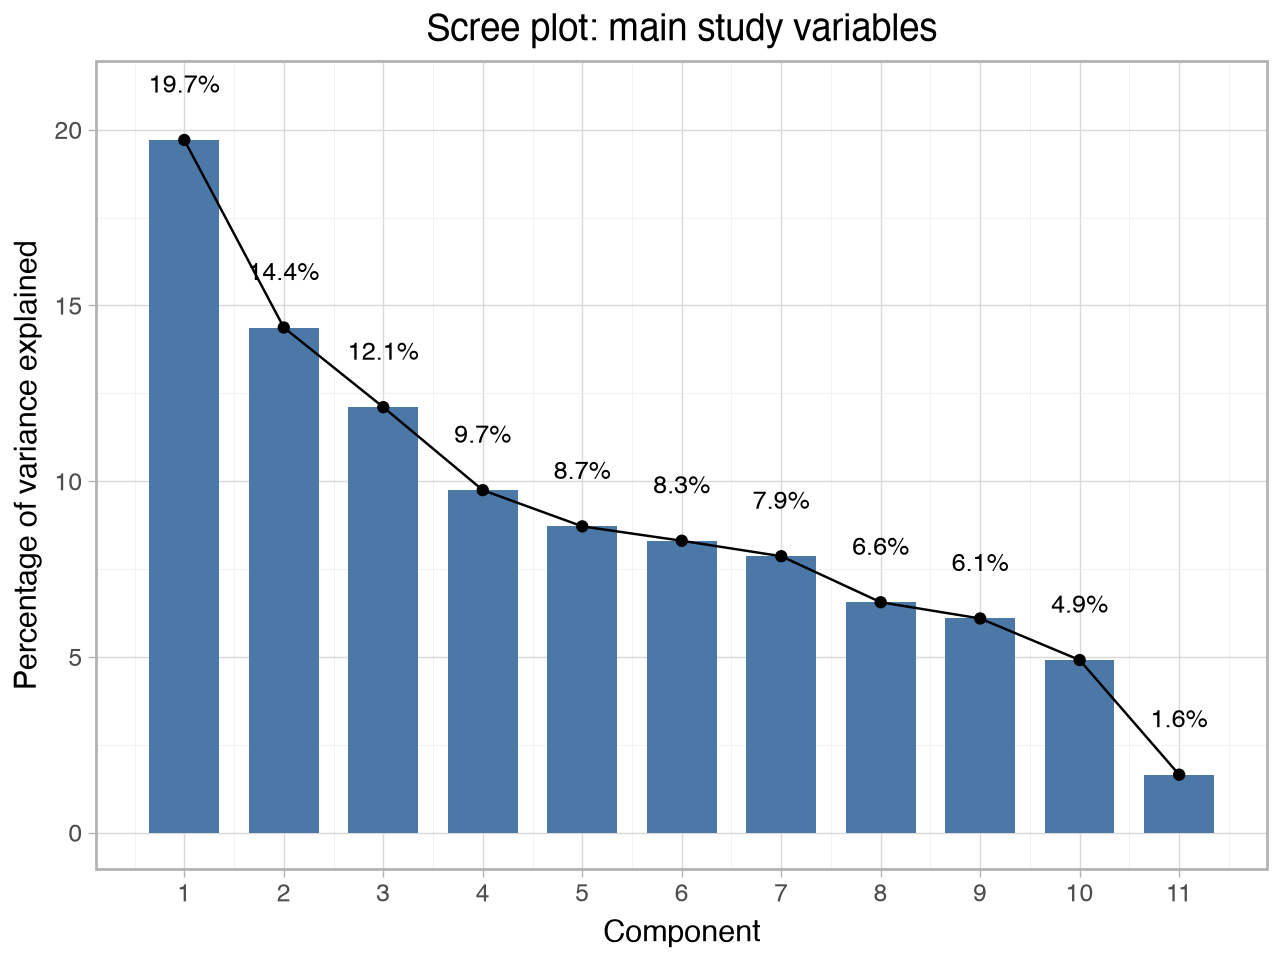

In [18]:
scree_plot(main_pca, "Scree plot: main study variables", "main_variables")  # scree plot for the main variables

### Interpretation (descriptive only)

**Sample.** The PCA uses **N = 1,444** respondents with complete data on all eleven variables, which is about 28% fewer than the full sample, mainly because of missing values on left–right placement (Q240) and parental education.

**Eigenvalues and scree plot.** Four components have eigenvalues above 1: **PC1 = 2.169** (19.7%), **PC2 = 1.582** (14.4%), **PC3 = 1.332** (12.1%) and **PC4 = 1.073** (9.7%), together explaining **55.9%** of the variance. The scree plot has no sharp elbow, and PC5 (0.959) and PC6 (0.914) are close to 1, so the Kaiser rule does not give a clear answer here. The main point is that the variables do **not** collapse into a few dimensions, which is consistent with the mostly weak correlations between them.

**PC1 (19.7%).** Positive weights: mother's education (0.484), father's education (0.410), science and faith/morality (0.322) and `mother_more_educated` (0.220). Negative weights: traditional gender-role attitudes (−0.370), authoritarian notions of democracy (−0.355), right-wing self-placement (−0.253) and religiosity (−0.252). PC1 is simply the **statistical axis** that captures the largest share of shared variance, so variables that are correlated with each other (as already shown in `03_correlations.ipynb` and `06_moderation.ipynb`) get weights on it. One could describe this pattern informally as "modern versus traditional", but that is an **interpretive label applied to a statistical axis**, not evidence of a real latent construct.

**PC2 (14.4%)** is defined by science optimism (0.579), regime evaluation (0.545) and liberal democracy (0.336), with smaller weights for parental education (around 0.3). The gender-role score has a very small weight on PC2 (0.014). This only means that it contributes little to **this component**. It does **not** mean that gender-role attitudes are unrelated to these variables: in `06_moderation.ipynb` (Section 5), for example, liberal notions and regime evaluation are both significantly associated with gender-role attitudes on their own.

**PC3 (12.1%)** mixes parental education (0.43 and 0.38), traditional gender-role attitudes (0.311), authoritarianism (0.294) and religiosity (0.291) on the positive side with science and faith/morality (−0.403) and liberal democracy (−0.313) on the negative side. We do not try to label it.

**PC4 (9.7%)** is almost entirely **`mother_more_educated`** (0.872), contrasted with father's education (−0.475). As expected for a **binary variable with only 6% "yes" answers**, it shares little variance with the other variables and ends up mostly on its own component.

**PC11.** The last component has a very small eigenvalue (0.181) and is made up of mother's education (0.687), father's education (−0.611) and `mother_more_educated` (−0.389). This simply reflects that `mother_more_educated` is calculated from Q277R and Q278R, so the three variables overlap almost completely. It is **not** our evidence about multicollinearity. The proper diagnostic is the variance inflation factors (VIFs) in `07_multivariate_models.ipynb`, which are all below 3.

## A.3 Plotting the First Two Components

As in Week 9, we plot each respondent's scores on PC1 and PC2. We colour the points by `mother_more_educated` to see whether respondents with a more educated mother occupy a different part of the space.

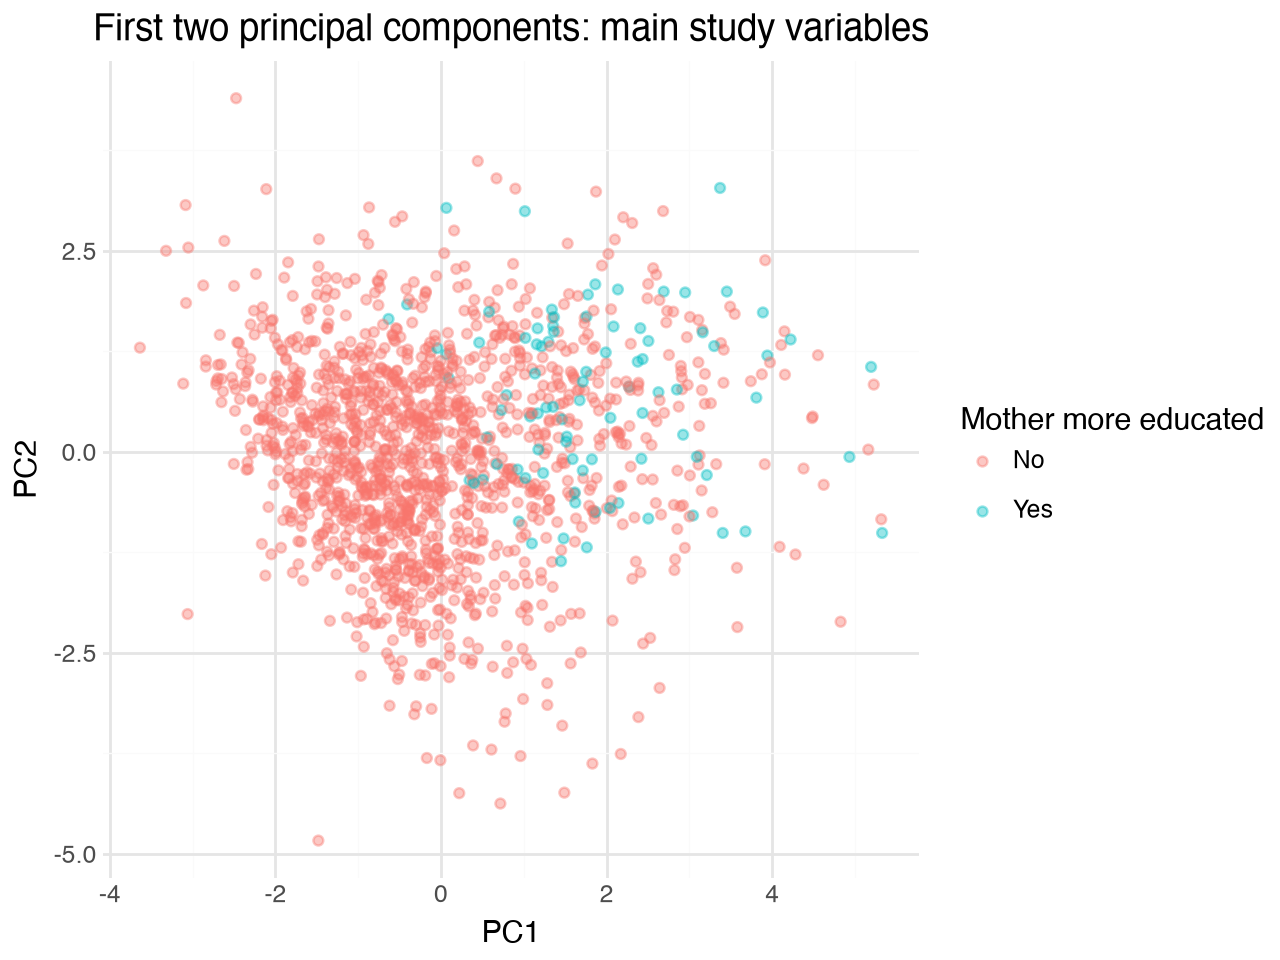

In [19]:
scores = main_pca.transform(main_X)  # each respondent's score on every component
plot_df = main_work.copy()  # copy of the data used in the PCA
plot_df["PC1"] = scores[:, 0]  # add the PC1 scores
plot_df["PC2"] = scores[:, 1]  # add the PC2 scores
plot_df["Mother more educated"] = np.where(plot_df["mother_more_educated"] == 1, "Yes", "No")  # readable labels

p = (
    ggplot(plot_df, aes("PC1", "PC2", color="Mother more educated"))  # PC1 on x, PC2 on y, coloured by group
    + geom_point(alpha=0.4, size=1.5)  # semi-transparent points
    + theme_minimal()  # minimal background, as in Week 9
    + labs(x="PC1", y="PC2", title="First two principal components: main study variables")  # labels
)
p.save(OUTPUT_FIGURES / "pca_main_variables_pc1_pc2.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

In [20]:
plot_df.groupby("Mother more educated")[["PC1", "PC2"]].agg(["mean", "std", "count"]).round(2)  # average PC scores per group

PC1               PC2            
                      mean   std count  mean   std count
Mother more educated                                    
No                   -0.12  1.41  1355 -0.04  1.26  1355
Yes                   1.86  1.21    89  0.65  1.05    89

### Interpretation (descriptive only)

Respondents whose mother is more educated than their father (n = 89 in this sample) have a higher average PC1 score (**1.86**, compared with **−0.12** for other respondents) and a slightly higher PC2 score (0.65 vs. −0.04).

This mostly reflects how PC1 is built: it has large weights for both parents' education levels, and a mother can only be "more educated than the father" if she has at least middle education. So the plot mainly shows the mother's education level, not the gap between the parents, which matches the within-maternal-education comparison in `05_mother_more_educated.ipynb` (Section 5). The two groups also overlap a lot, with points from both spread across the plot.

## Summary

We used PCA **exploratorily**, following the unrotated method from class, to examine the dimensional structure of our item sets. PCA does not validate psychological constructs. The labels we use come from item content and theory, and a rotated EFA (with polychoric correlations for the four-point gender items) would be more rigorous.

- **Gender-role items (supplementary evidence):** one main component (eigenvalue = 2.392, 59.8% of variance), with all four items having positive weights. Together with α = .767, this suggests that Q28–Q31 share **one broad dimension**, which supports the `traditional_gender_attitudes` score. Q28 ("when a mother works for pay, the children suffer") fits this dimension less well than the other three items.
- **Science and technology items (the clearest result):** two components (eigenvalues 1.997 and 1.590) instead of one weak scale (α = .460), matching **science optimism** (Q158, Q159, Q163) and **science and faith/morality** (Q160, Q161). Q162 behaves as a distinct item. We leave it out because its content (personal relevance of science) does not fit either moderator construct, not simply because PC3's eigenvalue (0.970) was just below 1.
- **Political culture items (exploratory scale construction):** three components with eigenvalues above 1 (PC4 = 0.927 is close to the cut-off), which mix several groups of items. We grouped the items by their content first and used the PCA, correlations and Cronbach's alpha as checks. This gave three **exploratory** sub-indices: **`authoritarian_democracy`** (Q242, Q245, Q248; α = .569, questionable), **`liberal_democracy`** (Q243, Q246; α = .592, questionable) and **`regime_evaluation`** (Q251, Q252; α = .797). **Q247** ("the state makes people's incomes equal") raises the authoritarian alpha to .643 and loads with those items, but by its content it is an economic-egalitarian item, so it is left out of the main index. A four-item version with Q247 is saved for sensitivity checks (r = .94 with the main index). **Q240** (left–right) is kept as a single item. Q249 is excluded because it overlaps with the outcome. Treating the 0 code as missing makes no difference to the indices.

The political sub-indices have been saved to `data/processed/WVS_Singapore_full_cleaned.csv` for the moderation analysis.

**Appendix (descriptive only):** the PCA on the main study variables mixes binary, ordinal and composite variables, uses only N = 1,444 respondents and does not answer our research question, so we draw no conclusions from it. Its first component is a statistical axis, not evidence of a "modern versus traditional" construct, and multicollinearity is assessed with VIFs in `07_multivariate_models.ipynb`, not with its last component.

**Limitations:** the values reported are PCA **component weights** (`pca.components_`), not conventional loadings (both are saved in `output/tables/`). PCA describes patterns of correlation and cannot tell us anything about cause and effect. The political sub-indices were built and checked in the same sample that we use to test our hypotheses, so they are **exploratory** measures rather than validated scales. Two of them (`authoritarian_democracy` and `liberal_democracy`) have questionable reliability (α < .60), and two have only two items.